# DWML A4: Bank Loan Approval Prediction Using Classification
### `Name: Shreeya Tapaswi`
### `Roll No - 31474`

---

## Problem Statement
An online bookstore wants to analyze the purchase patterns of its customers. The management believes that certain books are often bought together, and by identifying these associations, they can recommend relevant books, improve cross-selling, and design effective marketing campaigns.

**Task:**
- Apply the Apriori algorithm to find frequent itemsets with a minimum support of 40%.
- From the frequent itemsets, generate association rules with a minimum confidence of 60%.

---

## Dataset Description
The dataset contains historical transaction data from the online bookstore. It consists of the following key attributes:
- **TransactionID**: A unique identifier assigned to each individual customer transaction.
- **BooksPurchased**: A comma-separated list of books purchased by the customer during that specific transaction.


# 1. Install required library

In [98]:
# Install required library
!pip install mlxtend -q

# 2. Import libraries

In [99]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from mlxtend.frequent_patterns import apriori, association_rules

import warnings
warnings.filterwarnings("ignore")

# 3. Upload dataset

In [100]:
from google.colab import files

uploaded = files.upload()

Saving online_bookstore_apriori_transactions.csv to online_bookstore_apriori_transactions (2).csv


# 4. Load dataset

In [101]:
df = pd.read_csv("online_bookstore_apriori_transactions.csv")

print("Dataset loaded successfully!")
print("\nFirst 10 records:")
display(df.head(10))

Dataset loaded successfully!

First 10 records:


,TransactionID,BooksPurchased
0,T001,"Computer Networks, Data Science, Data Structur..."
1,T002,"Python Programming, SQL for Beginners"
2,T003,"Data Science, Python Programming"
3,T004,"Data Science, SQL for Beginners"
4,T005,"Machine Learning, Python Programming"
5,T006,"Python Programming, Statistics"
6,T007,"Machine Learning, SQL for Beginners"
7,T008,"Data Science, Data Structures, Machine Learning"
8,T009,"Machine Learning, Python Programming, SQL for ..."
9,T010,"Python Programming, SQL for Beginners, Statistics"


# 5. Dataset information

In [102]:
print("Number of transactions:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Number of transactions: 100
Number of columns: 2

Column names:
['TransactionID', 'BooksPurchased']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   TransactionID   100 non-null    object
 1   BooksPurchased  100 non-null    object
dtypes: object(2)
memory usage: 1.7+ KB


# 6. Missing values

In [103]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
TransactionID     0
BooksPurchased    0
dtype: int64


# 7. Missing value percentage

In [104]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("\nMissing value percentage:")
print(missing_percentage)


Missing value percentage:
TransactionID     0.0
BooksPurchased    0.0
dtype: float64


# 8. Visualize missing values

---



---



In [105]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


# 9. Duplicate records

In [106]:
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (100, 2)


# 11. Display cleaned dataset

In [107]:
display(df)

,TransactionID,BooksPurchased
0,T001,"Computer Networks, Data Science, Data Structur..."
1,T002,"Python Programming, SQL for Beginners"
2,T003,"Data Science, Python Programming"
3,T004,"Data Science, SQL for Beginners"
4,T005,"Machine Learning, Python Programming"
...,...,...
95,T096,"Deep Learning, Python Programming, Statistics"
96,T097,"Machine Learning, SQL for Beginners"
97,T098,"Data Science, Machine Learning"
98,T099,"Data Structures, Machine Learning, Python Prog..."


# 12. Create transactions

In [108]:
transactions = df["BooksPurchased"].apply(
    lambda x: [book.strip() for book in x.split(",")]
)

print("First 10 transactions:\n")

for i, transaction in enumerate(transactions.head(10), start=1):
    print(f"T{i:03d}: {transaction}")

First 10 transactions:

T001: ['Computer Networks', 'Data Science', 'Data Structures', 'Deep Learning', 'Operating Systems', 'Python Programming', 'SQL for Beginners', 'Web Development']
T002: ['Python Programming', 'SQL for Beginners']
T003: ['Data Science', 'Python Programming']
T004: ['Data Science', 'SQL for Beginners']
T005: ['Machine Learning', 'Python Programming']
T006: ['Python Programming', 'Statistics']
T007: ['Machine Learning', 'SQL for Beginners']
T008: ['Data Science', 'Data Structures', 'Machine Learning']
T009: ['Machine Learning', 'Python Programming', 'SQL for Beginners']
T010: ['Python Programming', 'SQL for Beginners', 'Statistics']


# 13. Find all unique items

In [109]:
all_books = sorted(
    set(book for transaction in transactions for book in transaction)
)

print("Total unique books:", len(all_books))

print("\nBooks available:")
for i, book in enumerate(all_books, start=1):
    print(i, ".", book)

Total unique books: 10

Books available:
1 . Computer Networks
2 . Data Science
3 . Data Structures
4 . Deep Learning
5 . Machine Learning
6 . Operating Systems
7 . Python Programming
8 . SQL for Beginners
9 . Statistics
10 . Web Development


# 14. Item frequency

In [110]:
book_counts = {}

for transaction in transactions:
    for book in transaction:
        book_counts[book] = book_counts.get(book, 0) + 1

book_frequency = pd.DataFrame(
    list(book_counts.items()),
    columns=["Book", "Transaction_Count"]
)

book_frequency = book_frequency.sort_values(
    by="Transaction_Count",
    ascending=False
)

display(book_frequency)

,Book,Transaction_Count
5,Python Programming,70
6,SQL for Beginners,60
8,Machine Learning,40
1,Data Science,40
9,Statistics,20
2,Data Structures,15
7,Web Development,10
0,Computer Networks,8
4,Operating Systems,6
3,Deep Learning,6


# 15. Calculate support

In [111]:
book_frequency["Support"] = (
    book_frequency["Transaction_Count"] / len(df)
)

book_frequency["Support_Percentage"] = (
    book_frequency["Support"] * 100
)

display(book_frequency)

,Book,Transaction_Count,Support,Support_Percentage
5,Python Programming,70,0.70,70.0
6,SQL for Beginners,60,0.60,60.0
8,Machine Learning,40,0.40,40.0
1,Data Science,40,0.40,40.0
9,Statistics,20,0.20,20.0
2,Data Structures,15,0.15,15.0
7,Web Development,10,0.10,10.0
0,Computer Networks,8,0.08,8.0
4,Operating Systems,6,0.06,6.0
3,Deep Learning,6,0.06,6.0


# 16. Item frequency graph

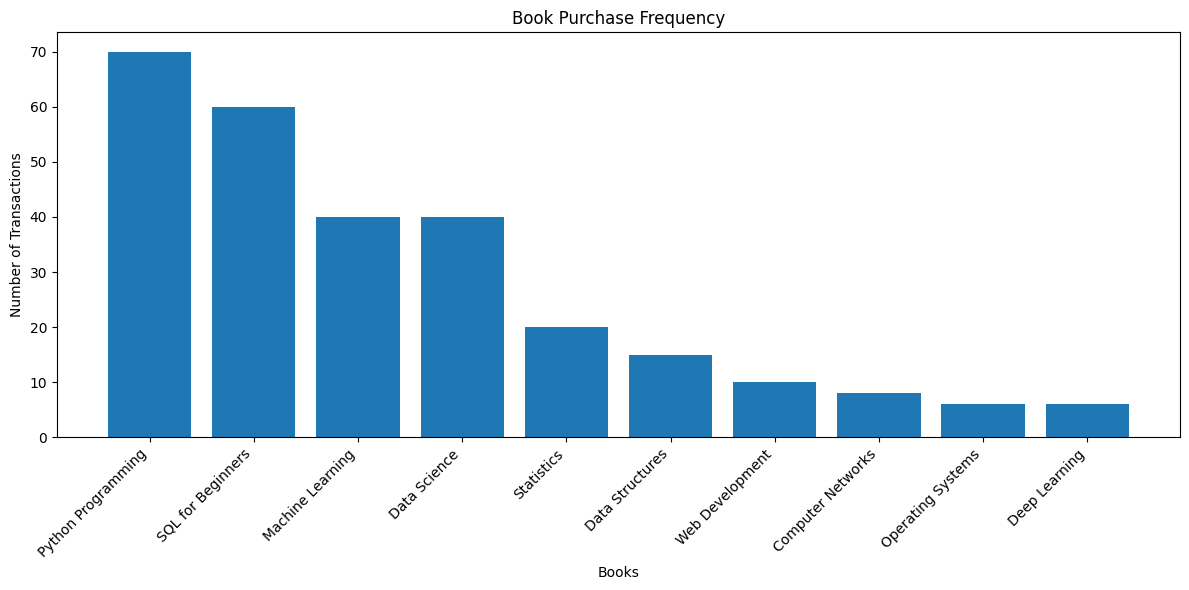

In [112]:
plt.figure(figsize=(12, 6))

plt.bar(
    book_frequency["Book"],
    book_frequency["Transaction_Count"]
)

plt.xlabel("Books")
plt.ylabel("Number of Transactions")
plt.title("Book Purchase Frequency")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

# 17. Item support graph

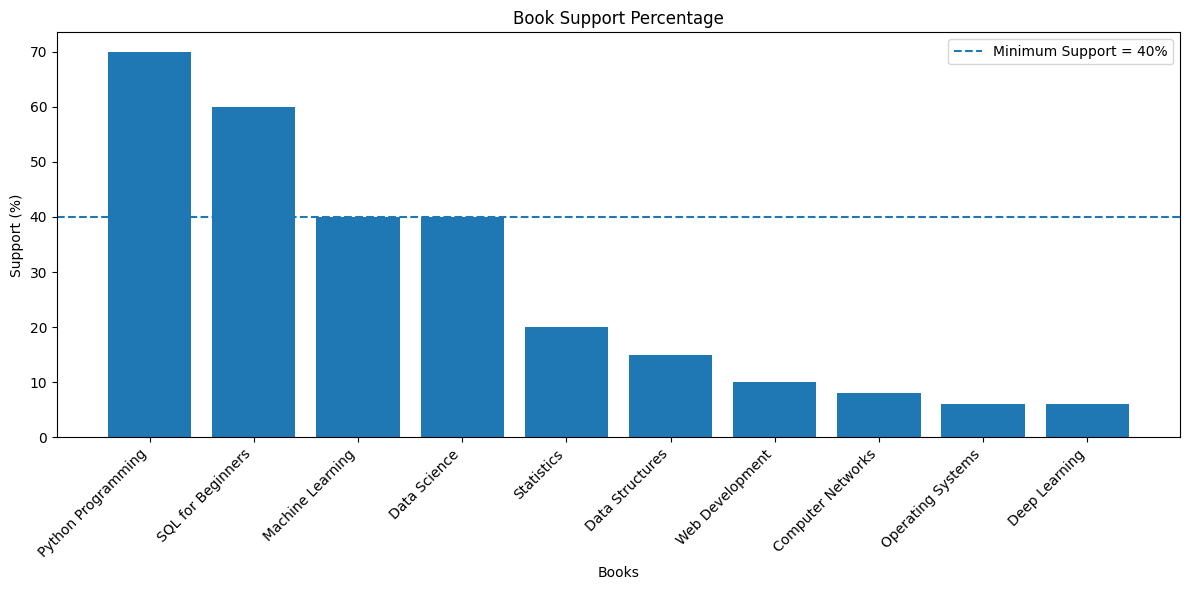

In [113]:
plt.figure(figsize=(12, 6))

plt.bar(
    book_frequency["Book"],
    book_frequency["Support_Percentage"]
)

plt.axhline(
    y=40,
    linestyle="--",
    label="Minimum Support = 40%"
)

plt.xlabel("Books")
plt.ylabel("Support (%)")
plt.title("Book Support Percentage")

plt.xticks(rotation=45, ha="right")
plt.legend()

plt.tight_layout()
plt.show()

# 18. Create transaction basket

In [114]:
basket = pd.DataFrame(
    0,
    index=df["TransactionID"],
    columns=all_books
)

for transaction_id, books in zip(
    df["TransactionID"],
    transactions
):
    for book in books:
        basket.loc[transaction_id, book] = 1

display(basket.head(10))

,Computer Networks,Data Science,Data Structures,Deep Learning,Machine Learning,Operating Systems,Python Programming,SQL for Beginners,Statistics,Web Development
TransactionID,,,,,,,,,,
T001,1,1,1,1,0,1,1,1,0,1
T002,0,0,0,0,0,0,1,1,0,0
T003,0,1,0,0,0,0,1,0,0,0
T004,0,1,0,0,0,0,0,1,0,0
T005,0,0,0,0,1,0,1,0,0,0
T006,0,0,0,0,0,0,1,0,1,0
T007,0,0,0,0,1,0,0,1,0,0
T008,0,1,1,0,1,0,0,0,0,0
T009,0,0,0,0,1,0,1,1,0,0


# 19. Basket shape and unique values

In [115]:
print("Basket shape:", basket.shape)

print("\nUnique values:")
for column in basket.columns:
    print(column, ":", basket[column].unique())

Basket shape: (100, 10)

Unique values:
Computer Networks : [1 0]
Data Science : [1 0]
Data Structures : [1 0]
Deep Learning : [1 0]
Machine Learning : [0 1]
Operating Systems : [1 0]
Python Programming : [1 0]
SQL for Beginners : [1 0]
Statistics : [0 1]
Web Development : [1 0]


# 20. Convert basket to Boolean

In [116]:
basket = basket.astype(bool)

display(basket.head(10))

,Computer Networks,Data Science,Data Structures,Deep Learning,Machine Learning,Operating Systems,Python Programming,SQL for Beginners,Statistics,Web Development
TransactionID,,,,,,,,,,
T001,True,True,True,True,False,True,True,True,False,True
T002,False,False,False,False,False,False,True,True,False,False
T003,False,True,False,False,False,False,True,False,False,False
T004,False,True,False,False,False,False,False,True,False,False
T005,False,False,False,False,True,False,True,False,False,False
T006,False,False,False,False,False,False,True,False,True,False
T007,False,False,False,False,True,False,False,True,False,False
T008,False,True,True,False,True,False,False,False,False,False
T009,False,False,False,False,True,False,True,True,False,False


# 21. Minimum support

In [117]:
min_support = 0.40

# 22. Apply Apriori

In [118]:
frequent_itemsets = apriori(
    basket,
    min_support=min_support,
    use_colnames=True
)

print("Frequent itemsets found:", len(frequent_itemsets))

display(frequent_itemsets)

Frequent itemsets found: 5


,support,itemsets
0,0.4,(Data Science)
1,0.4,(Machine Learning)
2,0.7,(Python Programming)
3,0.6,(SQL for Beginners)
4,0.4,"(Python Programming, SQL for Beginners)"


# 23. Support percentage

In [119]:
frequent_itemsets["Support_Percentage"] = (
    frequent_itemsets["support"] * 100
)

display(frequent_itemsets)

,support,itemsets,Support_Percentage
0,0.4,(Data Science),40.0
1,0.4,(Machine Learning),40.0
2,0.7,(Python Programming),70.0
3,0.6,(SQL for Beginners),60.0
4,0.4,"(Python Programming, SQL for Beginners)",40.0


# 24. Itemset size

In [120]:
frequent_itemsets["Itemset_Size"] = (
    frequent_itemsets["itemsets"].apply(len)
)

display(
    frequent_itemsets[
        ["itemsets", "Itemset_Size", "support", "Support_Percentage"]
    ]
)

,itemsets,Itemset_Size,support,Support_Percentage
0,(Data Science),1,0.4,40.0
1,(Machine Learning),1,0.4,40.0
2,(Python Programming),1,0.7,70.0
3,(SQL for Beginners),1,0.6,60.0
4,"(Python Programming, SQL for Beginners)",2,0.4,40.0


# 25. Sort frequent itemsets

In [121]:
frequent_itemsets = frequent_itemsets.sort_values(
    by="support",
    ascending=False
)

display(frequent_itemsets)

,support,itemsets,Support_Percentage,Itemset_Size
2,0.7,(Python Programming),70.0,1
3,0.6,(SQL for Beginners),60.0,1
0,0.4,(Data Science),40.0,1
1,0.4,(Machine Learning),40.0,1
4,0.4,"(Python Programming, SQL for Beginners)",40.0,2


# 26. Print frequent itemsets

In [122]:
print("FREQUENT ITEMSETS (Minimum Support = 40%)")
print("=" * 60)

for _, row in frequent_itemsets.iterrows():

    items = ", ".join(sorted(row["itemsets"]))

    print(
        f"{{{items}}}  -->  "
        f"Support = {row['Support_Percentage']:.2f}%"
    )

FREQUENT ITEMSETS (Minimum Support = 40%)
{Python Programming}  -->  Support = 70.00%
{SQL for Beginners}  -->  Support = 60.00%
{Data Science}  -->  Support = 40.00%
{Machine Learning}  -->  Support = 40.00%
{Python Programming, SQL for Beginners}  -->  Support = 40.00%


# 27. Frequent 1-itemsets

In [123]:
one_itemsets = frequent_itemsets[
    frequent_itemsets["Itemset_Size"] == 1
]

print("Frequent 1-Itemsets:")
display(one_itemsets)

Frequent 1-Itemsets:


,support,itemsets,Support_Percentage,Itemset_Size
2,0.7,(Python Programming),70.0,1
3,0.6,(SQL for Beginners),60.0,1
0,0.4,(Data Science),40.0,1
1,0.4,(Machine Learning),40.0,1


# 28. Frequent 2-itemsets

In [124]:
two_itemsets = frequent_itemsets[
    frequent_itemsets["Itemset_Size"] == 2
]

print("Frequent 2-Itemsets:")
display(two_itemsets)

Frequent 2-Itemsets:


,support,itemsets,Support_Percentage,Itemset_Size
4,0.4,"(Python Programming, SQL for Beginners)",40.0,2


# 29. Frequent itemsets graph

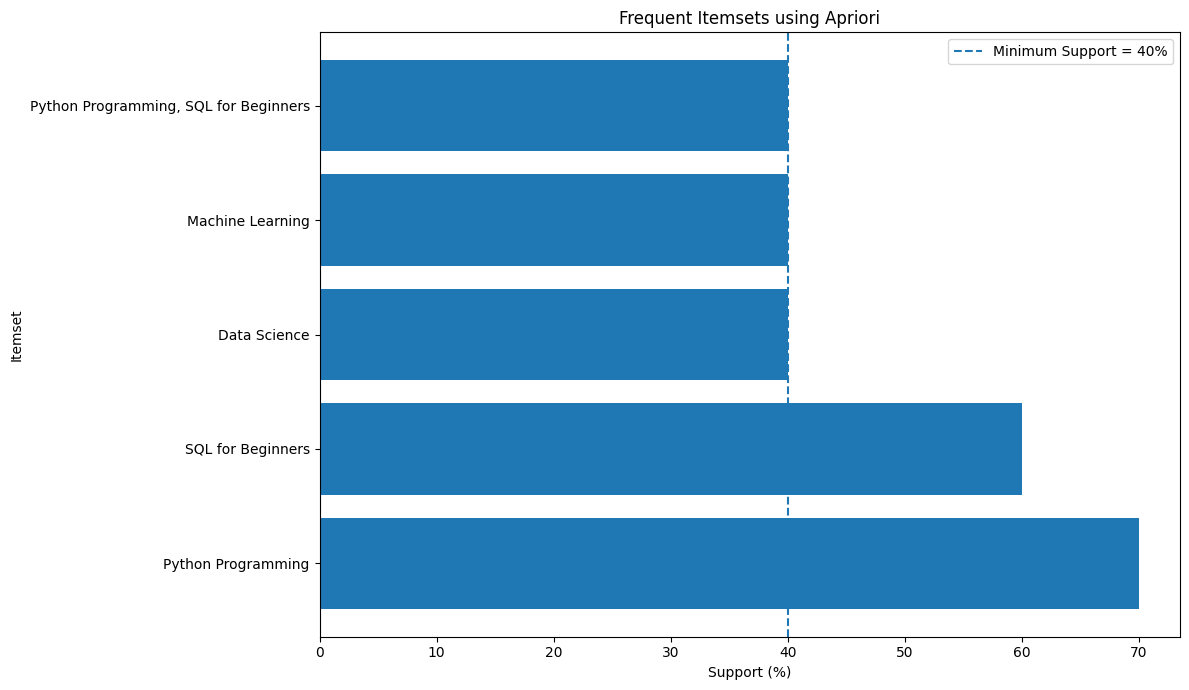

In [125]:
itemset_labels = [
    ", ".join(sorted(itemset))
    for itemset in frequent_itemsets["itemsets"]
]

support_values = frequent_itemsets["Support_Percentage"]

plt.figure(figsize=(12, 7))

plt.barh(
    itemset_labels,
    support_values
)

plt.axvline(
    x=40,
    linestyle="--",
    label="Minimum Support = 40%"
)

plt.xlabel("Support (%)")
plt.ylabel("Itemset")
plt.title("Frequent Itemsets using Apriori")

plt.legend()
plt.tight_layout()
plt.show()

# 30. Minimum confidence

In [126]:
min_confidence = 0.60

# 31. Generate association rules

In [127]:
rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=min_confidence
)

print("Number of association rules:", len(rules))

display(rules)

Number of association rules: 1


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(SQL for Beginners),(Python Programming),0.6,0.7,0.4,0.666667,0.952381,1.0,-0.02,0.9,-0.111111,0.444444,-0.111111,0.619048


# 32. Select important columns

In [128]:
rules_result = rules[
    [
        "antecedents",
        "consequents",
        "support",
        "confidence",
        "lift"
    ]
].copy()

display(rules_result)

,antecedents,consequents,support,confidence,lift
0,(SQL for Beginners),(Python Programming),0.4,0.666667,0.952381


# 33. Convert support and confidence into percentage

In [129]:
rules_result["support"] = (
    rules_result["support"] * 100
)

rules_result["confidence"] = (
    rules_result["confidence"] * 100
)

display(rules_result)

,antecedents,consequents,support,confidence,lift
0,(SQL for Beginners),(Python Programming),40.0,66.666667,0.952381


# 34. Create readable rules

In [130]:
readable_rules = []

for _, row in rules.iterrows():

    antecedent = ", ".join(
        sorted(row["antecedents"])
    )

    consequent = ", ".join(
        sorted(row["consequents"])
    )

    readable_rules.append({
        "Rule": f"{antecedent} -> {consequent}",
        "Support (%)": row["support"] * 100,
        "Confidence (%)": row["confidence"] * 100,
        "Lift": row["lift"]
    })

rules_df = pd.DataFrame(readable_rules)

display(rules_df)

,Rule,Support (%),Confidence (%),Lift
0,SQL for Beginners -> Python Programming,40.0,66.666667,0.952381


# 35. Strong association rules

In [131]:
strong_rules = rules_df[
    rules_df["Confidence (%)"] >= 60
].copy()

strong_rules = strong_rules.sort_values(
    by="Confidence (%)",
    ascending=False
)

print("Strong Association Rules:")
display(strong_rules)

Strong Association Rules:


,Rule,Support (%),Confidence (%),Lift
0,SQL for Beginners -> Python Programming,40.0,66.666667,0.952381


# 36. Rules sorted by confidence

In [132]:
rules_by_confidence = rules_df.sort_values(
    by="Confidence (%)",
    ascending=False
)

display(rules_by_confidence)

,Rule,Support (%),Confidence (%),Lift
0,SQL for Beginners -> Python Programming,40.0,66.666667,0.952381


# 37. Rules sorted by lift

In [133]:
rules_by_lift = rules_df.sort_values(
    by="Lift",
    ascending=False
)

display(rules_by_lift)

,Rule,Support (%),Confidence (%),Lift
0,SQL for Beginners -> Python Programming,40.0,66.666667,0.952381


# 38. Confidence graph

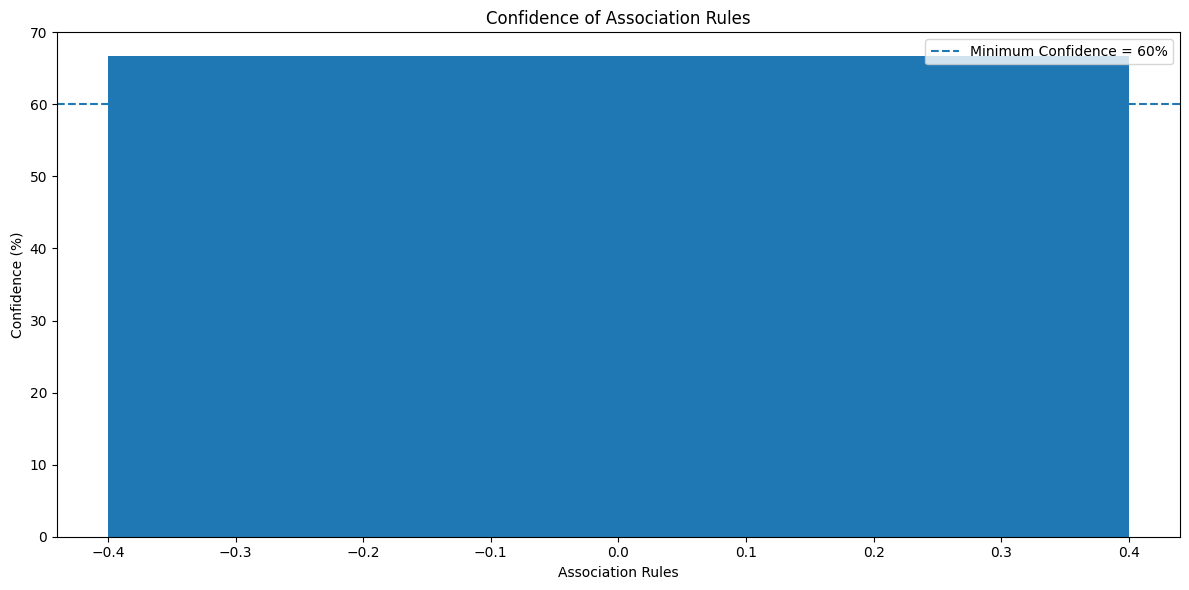

In [134]:
plt.figure(figsize=(12, 6))

plt.bar(
    range(len(rules_df)),
    rules_df["Confidence (%)"]
)

plt.axhline(
    y=60,
    linestyle="--",
    label="Minimum Confidence = 60%"
)

plt.xlabel("Association Rules")
plt.ylabel("Confidence (%)")
plt.title("Confidence of Association Rules")

plt.legend()
plt.tight_layout()
plt.show()

# 39. Support vs Confidence graph

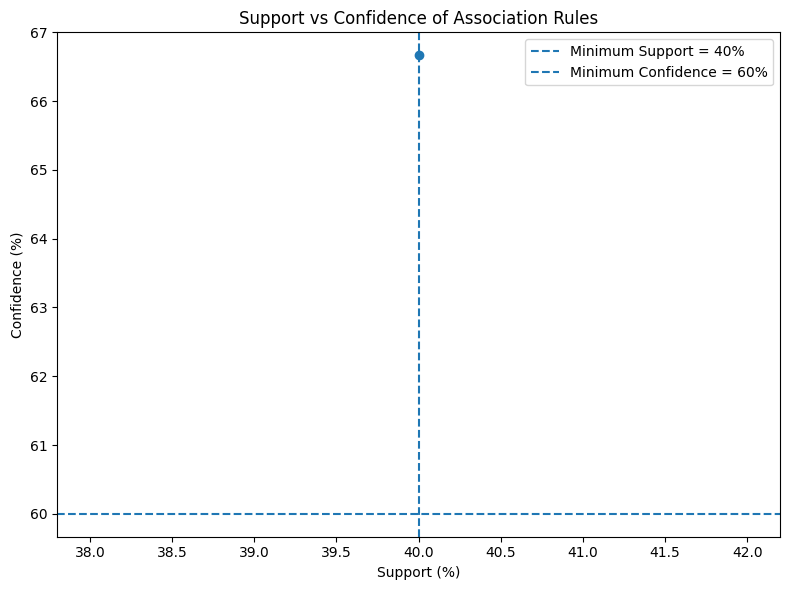

In [135]:
plt.figure(figsize=(8, 6))

plt.scatter(
    rules_df["Support (%)"],
    rules_df["Confidence (%)"]
)

plt.xlabel("Support (%)")
plt.ylabel("Confidence (%)")

plt.title("Support vs Confidence of Association Rules")

plt.axvline(
    x=40,
    linestyle="--",
    label="Minimum Support = 40%"
)

plt.axhline(
    y=60,
    linestyle="--",
    label="Minimum Confidence = 60%"
)

plt.legend()

plt.tight_layout()

plt.show()

# 40. Lift graph

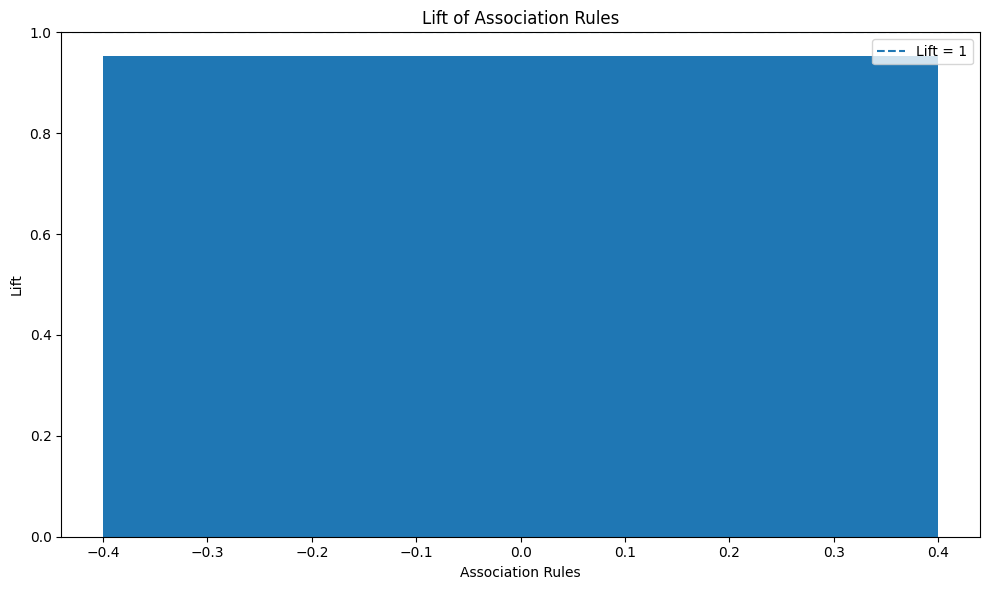

In [136]:
plt.figure(figsize=(10, 6))

plt.bar(
    range(len(rules_df)),
    rules_df["Lift"]
)

plt.axhline(
    y=1,
    linestyle="--",
    label="Lift = 1"
)

plt.xlabel("Association Rules")
plt.ylabel("Lift")
plt.title("Lift of Association Rules")

plt.legend()
plt.tight_layout()
plt.show()

# 41. Final association rules

In [137]:
print("FINAL ASSOCIATION RULES")
print("=" * 80)

for _, row in rules_df.iterrows():

    print(f"\nRule: {row['Rule']}")
    print(f"Support: {row['Support (%)']:.2f}%")
    print(f"Confidence: {row['Confidence (%)']:.2f}%")
    print(f"Lift: {row['Lift']:.2f}")

FINAL ASSOCIATION RULES

Rule: SQL for Beginners -> Python Programming
Support: 40.00%
Confidence: 66.67%
Lift: 0.95


# 42. Strongest rule based on confidence

In [138]:
strongest_rule = rules_df.loc[
    rules_df["Confidence (%)"].idxmax()
]

print("STRONGEST RULE BASED ON CONFIDENCE")
print("=" * 50)

print("Rule:", strongest_rule["Rule"])
print(
    "Support:",
    f"{strongest_rule['Support (%)']:.2f}%"
)
print(
    "Confidence:",
    f"{strongest_rule['Confidence (%)']:.2f}%"
)
print(
    "Lift:",
    f"{strongest_rule['Lift']:.2f}"
)

STRONGEST RULE BASED ON CONFIDENCE
Rule: SQL for Beginners -> Python Programming
Support: 40.00%
Confidence: 66.67%
Lift: 0.95


# 43. Highest lift rule

In [139]:
highest_lift_rule = rules_df.loc[
    rules_df["Lift"].idxmax()
]

print("RULE WITH HIGHEST LIFT")
print("=" * 50)

print("Rule:", highest_lift_rule["Rule"])
print(
    "Support:",
    f"{highest_lift_rule['Support (%)']:.2f}%"
)
print(
    "Confidence:",
    f"{highest_lift_rule['Confidence (%)']:.2f}%"
)
print(
    "Lift:",
    f"{highest_lift_rule['Lift']:.2f}"
)

RULE WITH HIGHEST LIFT
Rule: SQL for Beginners -> Python Programming
Support: 40.00%
Confidence: 66.67%
Lift: 0.95


# 44. Shopping recommendation insights

In [140]:
print("BOOK RECOMMENDATION INSIGHTS")
print("=" * 70)

for _, row in rules_df.iterrows():

    print(
        f"If a customer purchases {row['Rule'].split(' -> ')[0]}, "
        f"recommend {row['Rule'].split(' -> ')[1]}."
    )

    print(
        f"Confidence: {row['Confidence (%)']:.2f}% | "
        f"Lift: {row['Lift']:.2f}"
    )

    print()

BOOK RECOMMENDATION INSIGHTS
If a customer purchases SQL for Beginners, recommend Python Programming.
Confidence: 66.67% | Lift: 0.95



# 45. Save results

In [141]:
frequent_itemsets.to_csv(
    "frequent_itemsets.csv",
    index=False
)

rules_df.to_csv(
    "association_rules.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!


# 46. Download frequent itemsets

In [142]:
# Display Frequent Itemsets instead of downloading
print("Frequent Itemsets:")
display(frequent_itemsets)

Frequent Itemsets:


,support,itemsets,Support_Percentage,Itemset_Size
2,0.7,(Python Programming),70.0,1
3,0.6,(SQL for Beginners),60.0,1
0,0.4,(Data Science),40.0,1
1,0.4,(Machine Learning),40.0,1
4,0.4,"(Python Programming, SQL for Beginners)",40.0,2


# 47. Download association rules

In [143]:
# Display Association Rules instead of downloading
print("Association Rules:")
display(rules_df)

Association Rules:


,Rule,Support (%),Confidence (%),Lift
0,SQL for Beginners -> Python Programming,40.0,66.666667,0.952381


# 48. Download item frequency

In [144]:
# Save and Display Item Frequency instead of downloading
book_frequency.to_csv("item_frequency.csv", index=False)
print("Item Frequency:")
display(book_frequency)

Item Frequency:


,Book,Transaction_Count,Support,Support_Percentage
5,Python Programming,70,0.70,70.0
6,SQL for Beginners,60,0.60,60.0
8,Machine Learning,40,0.40,40.0
1,Data Science,40,0.40,40.0
9,Statistics,20,0.20,20.0
2,Data Structures,15,0.15,15.0
7,Web Development,10,0.10,10.0
0,Computer Networks,8,0.08,8.0
4,Operating Systems,6,0.06,6.0
3,Deep Learning,6,0.06,6.0


## Conclusion

The Apriori algorithm was successfully applied to the online bookstore
transaction dataset to identify frequently purchased books and
association rules.

A minimum support threshold of 40% was used to identify frequent
itemsets, and a minimum confidence threshold of 60% was used to
generate strong association rules.

The discovered relationships can help the online bookstore provide
personalized book recommendations, create book bundles, improve
cross-selling, and design targeted marketing campaigns.

Therefore, Apriori association-rule mining can be effectively used to
analyze customer purchasing patterns and support business
decision-making.